In [1]:
# import dataset

import pandas as pd

df = pd.read_csv("hku_cc_main_dataset_imputed.csv")

def report_df():
    summary_df = pd.DataFrame({
        "Data Type": df.dtypes,
        "Missing (%)": (df.isnull().mean() * 100).round(2)
    })

    print(summary_df)
    print(df.columns)

report_df()


                             Data Type  Missing (%)
course_code                     object         0.00
course_name                     object         1.48
aoi                             object         0.00
is_online                        int64         0.00
is_comm_intensive                int64         0.00
sdg_01                           int64         0.00
sdg_02                           int64         0.00
sdg_03                           int64         0.00
sdg_04                           int64         0.00
sdg_05                           int64         0.00
sdg_06                           int64         0.00
sdg_07                           int64         0.00
sdg_08                           int64         0.00
sdg_09                           int64         0.00
sdg_10                           int64         0.00
sdg_11                           int64         0.00
sdg_12                           int64         0.00
sdg_13                           int64         0.00
sdg_14      

In [ ]:
# modify dataset

# report_df()

Pearson Correlation Matrix:
                        sis_mean_effectiveness  llm_sentiment_score
sis_mean_effectiveness                1.000000             0.161349
llm_sentiment_score                   0.161349             1.000000


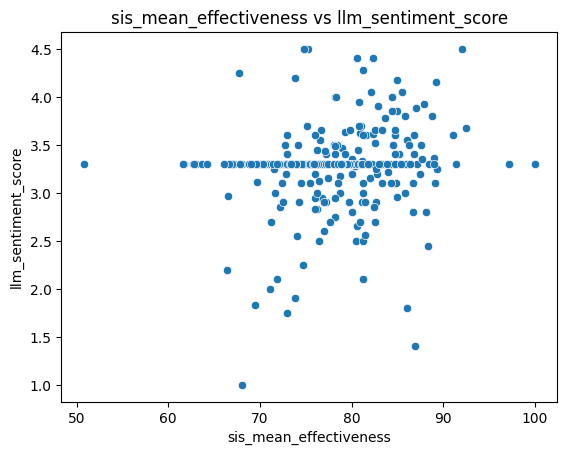

In [3]:
# analyze the relationship between "sis_mean_effectiveness" and "llm_sentiment_score"

import seaborn as sns
import matplotlib.pyplot as plt

corr = df[["sis_mean_effectiveness", "llm_sentiment_score"]].corr(method="pearson")
print("Pearson Correlation Matrix:")
print(corr)

sns.scatterplot(data=df, x="sis_mean_effectiveness", y="llm_sentiment_score")
plt.title("sis_mean_effectiveness vs llm_sentiment_score")
plt.show()

# seems like "sis_mean_effectiveness" and "llm_sentiment_score" are quite unrelated
# then lets ignore "llm_sentiment_score"

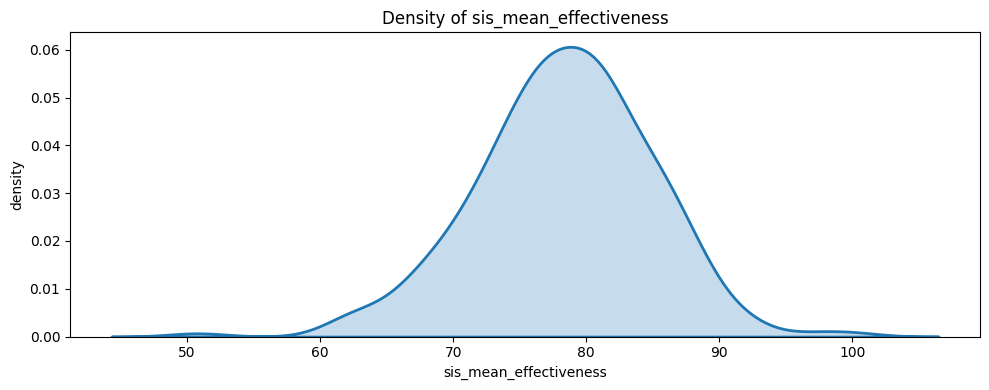

In [21]:
import seaborn as sns

X = df[[
	'is_online', 'is_comm_intensive',
	# 'sdg_01', 'sdg_02', 'sdg_03', 'sdg_04', 'sdg_05', 'sdg_06', 'sdg_07',
	# 'sdg_08', 'sdg_09', 'sdg_10', 'sdg_11', 'sdg_12', 'sdg_13', 'sdg_14',
	# 'sdg_15', 'sdg_16', 'sdg_17',
	'study_load_total', 'hours_lectures', 'hours_tutorials',
	'hours_self_study', 'hours_assessment', 'weight_essay',
	'weight_quiz_exam', 'weight_presentation', 'weight_participation',
	'weight_project', 'quota_per_semester',
	'aoi_CCCH', 'aoi_CCGL',
	'aoi_CCHU', 'aoi_CCST', 'sem_both', 'sem_sem1', 'sem_sem2',
	'sem_unknown'
]]
y = df["sis_mean_effectiveness"]

plt.figure(figsize=(10, 4))
sns.kdeplot(y, fill=True, linewidth=2)
plt.title("Density of sis_mean_effectiveness")
plt.xlabel("sis_mean_effectiveness")
plt.ylabel("density")
plt.tight_layout()
plt.show()


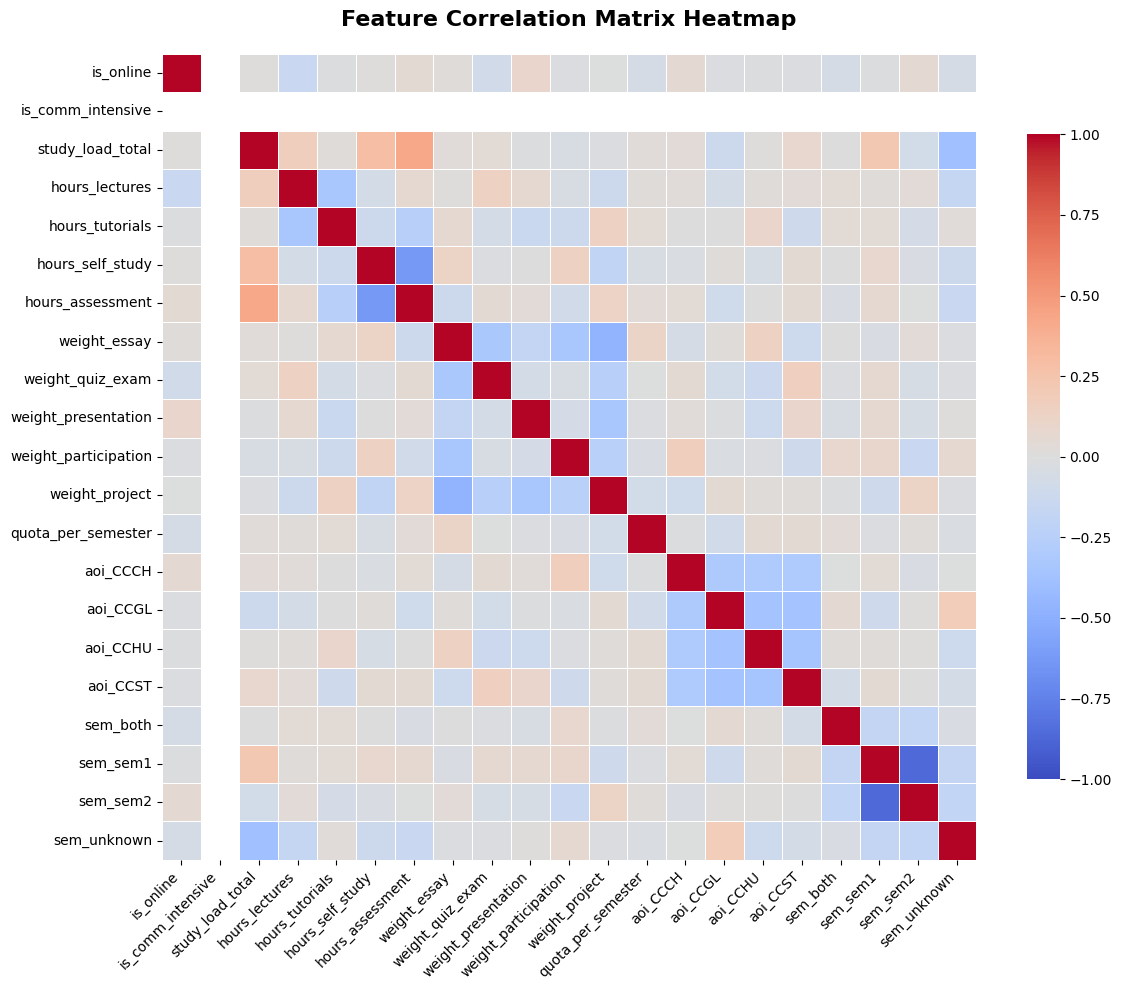

In [22]:
# check multicollinearity between features

from statsmodels.stats.outliers_influence import variance_inflation_factor

# correlation heatmap

corr = X.corr(method="pearson")

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr, 
    annot=False,            # Set to True if you want numbers inside cells (can get crowded with 20 features)
    cmap='coolwarm',        # Diverging colormap: Blue = negative correlation, Red = positive correlation
    vmin=-1, vmax=1,        # Fixes the color scale from -1 to 1
    linewidths=0.5,         # Adds faint grid lines between cells
    cbar_kws={"shrink": .8} # Scales the color bar nicely
)

plt.title("Feature Correlation Matrix Heatmap", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

plt.show()

# vif

# vif_data = pd.DataFrame()
# vif_data["Feature"] = X.columns
# vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# vif_data = vif_data.sort_values(by="VIF", ascending=False)
# print(vif_data)

In [ ]:
# create train / test set

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [24]:
# regress

import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV, LinearRegression
from sklearn.pipeline import Pipeline

alphas = np.logspace(-4, 3, 30)   # 1e-4 ... 1e3

ridge = RidgeCV(alphas=alphas, cv=5)          # efficient GCV-ish, fast
lasso = LassoCV(alphas=alphas, cv=5, max_iter=50000, n_jobs=-1)

ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

print("ridge alpha:", ridge.alpha_)
print("lasso alpha:", lasso.alpha_)

print("ridge coeffs:")
print(pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": ridge.coef_
}))
print("lasso coeffs:")
print(pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso.coef_
}))



ridge alpha: 62.10169418915616
lasso alpha: 0.2395026619987486
ridge coeffs:
                 Feature  Coefficient
0              is_online     0.828262
1      is_comm_intensive     0.000000
2       study_load_total    -0.790348
3         hours_lectures     0.224190
4        hours_tutorials    -0.014836
5       hours_self_study    -0.255317
6       hours_assessment    -0.391974
7           weight_essay    -0.274155
8       weight_quiz_exam    -0.166748
9    weight_presentation    -0.084405
10  weight_participation    -0.346733
11        weight_project     0.659526
12    quota_per_semester     0.717628
13              aoi_CCCH    -0.607837
14              aoi_CCGL    -0.203097
15              aoi_CCHU     0.418659
16              aoi_CCST     0.345104
17              sem_both     0.554846
18              sem_sem1    -0.533793
19              sem_sem2     0.147478
20           sem_unknown     0.461906
lasso coeffs:
                 Feature  Coefficient
0              is_online     0.7818

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 3.2654229225736344, tolerance: 0.6699100419653178
  model = cd_fast.enet_coordinate_descent_gram(


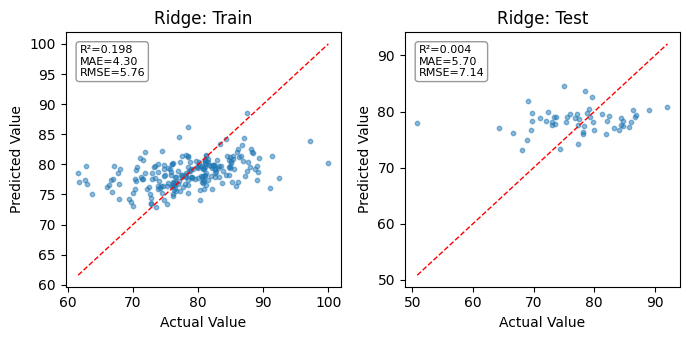

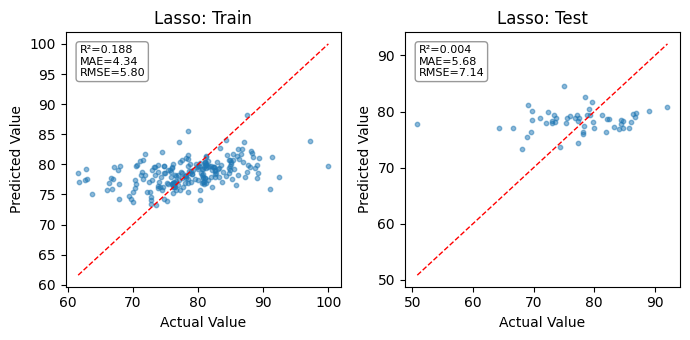

(None,)

In [25]:
# evaluate

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def eval_model(name, model):
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)

    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

    for ax, (label, real, pred) in zip(
        axes,
        [("Train", y_train, pred_tr), ("Test", y_test, pred_te)],
    ):
        ax.scatter(real, pred, s=10, alpha=0.5)
        lims = [min(real.min(), pred.min()), max(real.max(), pred.max())]
        ax.plot(lims, lims, "r--", lw=1)
        ax.set_xlabel("Actual Value")
        ax.set_ylabel("Predicted Value")
        ax.set_title(f"{name}: {label}")
        ax.text(
        0.05, 0.95,
        f"R²={r2_score(real, pred):.3f}\n"
        f"MAE={mean_absolute_error(real, pred):.2f}\n"
        f"RMSE={np.sqrt(mean_squared_error(real, pred)):.2f}",
        transform=ax.transAxes, va="top", fontsize=8,
        bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.8),
    )

    plt.tight_layout()
    plt.show()
    
eval_model("Ridge", ridge),
eval_model("Lasso", lasso),


In [ ]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# X must be raw/unscaled predictors; y is sis_mean_effectiveness.
# Exclude rows with missing target values.
valid = y.notna()
X_valid = X.loc[valid].copy()
y_valid = y.loc[valid].astype(float)

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

models = {
    "Mean baseline": make_pipeline(
        SimpleImputer(strategy="median"),
        DummyRegressor(strategy="mean"),
    ),
    "Ridge": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        RidgeCV(alphas=np.logspace(-3, 3, 13), cv=5),
    ),
}

for name, model in models.items():
    scores = cross_validate(model, X_valid, y_valid, cv=cv, scoring=scoring)
    print(
        f"{name}: "
        f"MAE={-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}, "
        f"RMSE={-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}, "
        f"R²={scores['test_r2'].mean():.3f} ± {scores['test_r2'].std():.3f}"
    )

Mean baseline: MAE=5.16 ± 0.53, RMSE=6.60 ± 0.70, R²=-0.029 ± 0.039
Ridge: MAE=4.96 ± 0.51, RMSE=6.37 ± 0.65, R²=0.035 ± 0.109


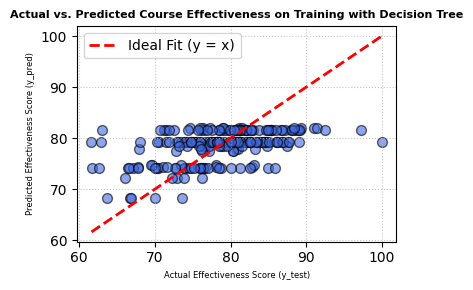

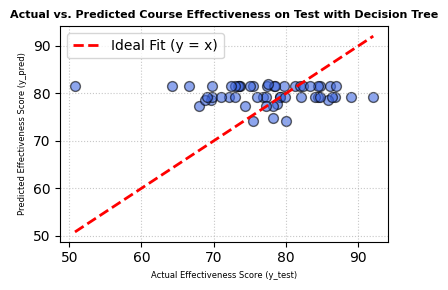

MAE=5.955210109026769
RMSE=7.9099527387384905
R^2=-0.22294238840797087


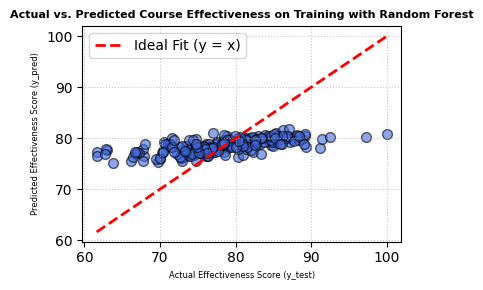

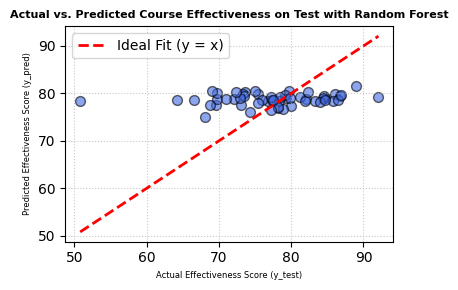

MAE=5.453831530661116
RMSE=7.147558137830601
R^2=0.0014412669528505173


In [ ]:
# decision tree regression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

tree = DecisionTreeRegressor(
    max_depth=4, 
    min_samples_leaf=5, 
    random_state=42
)

tree.fit(X_train, y_train)

eval_model("Decision Tree", tree)

forest = RandomForestRegressor(
    n_estimators=300,        # More trees for a stable average
    max_depth=4,             # Keep trees shallow to prevent overfitting on 300 rows
    min_samples_leaf=8,      # Force leaves to have enough data points to be meaningful
    max_features='sqrt',     # Look at a subset of features per split to reduce correlation
    random_state=42
)

forest.fit(X_train, y_train)

eval_model("Random Forest", forest)

In [ ]:
# ditch effectiveness scoring, use categories

q25 = np.percentile(y, 25)
q75 = np.percentile(y, 75)

print(f"Q25 Cutoff: {q25:.2f}")
print(f"Q75 Cutoff: {q75:.2f}")

bins = [-np.inf, q25, q75, np.inf]
labels = ['Poor', 'Avg', 'Good']

y_binned = pd.cut(y, bins=bins, labels=labels)

print("\nClass Distribution:")
print(y_binned.value_counts())

Q25 Cutoff: 74.28
Q75 Cutoff: 82.58

Class Distribution:
sis_mean_effectiveness
Avg     133
Poor     69
Good     68
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X, y_binned, test_size=0.2, stratify=y_binned, random_state=42
)

scaler = StandardScaler()
X_train_2 = scaler.fit_transform(X_train_2)
X_test_2 = scaler.transform(X_test_2)

classifier = LogisticRegression(
    penalty='l1',
    solver='saga', 
    C=1,
    max_iter=1000, 
    random_state=42
)

classifier.fit(X_train_2, y_train_2)

y_train_pred_2 = classifier.predict(X_train_2)
y_pred_2 = classifier.predict(X_test_2)

print("=== Classification Report ===")
print("w/ train:")
print(classification_report(y_train_2, y_train_pred_2))
print("w/ test:")
print(classification_report(y_test_2, y_pred_2))

print("\n=== Confusion Matrix ===")
print("w/ train:")
print(confusion_matrix(y_train_2, y_train_pred_2, labels=labels))
print("w/ test:")
print(confusion_matrix(y_test_2, y_pred_2, labels=labels))

=== Classification Report ===
w/ train:
              precision    recall  f1-score   support

         Avg       0.63      0.73      0.68       106
        Good       0.66      0.64      0.65        55
        Poor       0.56      0.42      0.48        55

    accuracy                           0.62       216
   macro avg       0.62      0.59      0.60       216
weighted avg       0.62      0.62      0.62       216

w/ test:
              precision    recall  f1-score   support

         Avg       0.50      0.56      0.53        27
        Good       0.22      0.15      0.18        13
        Poor       0.27      0.29      0.28        14

    accuracy                           0.39        54
   macro avg       0.33      0.33      0.33        54
weighted avg       0.37      0.39      0.38        54


=== Confusion Matrix ===
w/ train:
[[23 28  4]
 [15 77 14]
 [ 3 17 35]]
w/ test:
[[ 4  9  1]
 [ 6 15  6]
 [ 5  6  2]]
